# Phase A — RQ3 (ML prediction) and RQ4 (SHAP) on the authors' released dataset

Re-runs end-to-end: `jupyter nbconvert --to notebook --execute --inplace notebooks/phaseA_ml_shap.ipynb`
(from the repo root, inside the `ehrepl` conda env). Requires Phase 0 to have produced
`results/reproduce/asis/metric_groups.csv` and `results/reproduce/fixed/predictors_simplified.csv`.

In [1]:
import os, subprocess, sys
from pathlib import Path
ROOT = Path.cwd() if (Path.cwd() / 'src').exists() else Path.cwd().parent
os.chdir(ROOT)
sys.path.insert(0, str(ROOT / 'src' / 'ml'))
import pandas as pd
from IPython.display import Image, Markdown, display
from common import PROJECTS, feature_sets, load_project
pd.set_option('display.width', 200)
print(ROOT)

D:\Software Maint Project\exception-handling-replication


## Data: files with ≥1 catch block (the paper's presented setting)

In [2]:
rows = []
for p in PROJECTS:
    d = load_project(p)
    y = d['Distinct.count.of.Issue.Key.POST'] > 0
    rows.append(dict(project=p, files=len(d), defective=int(y.sum()), prevalence=round(y.mean(), 3)))
display(pd.DataFrame(rows))
display(pd.DataFrame({k: [len(v)] for k, v in feature_sets().items()}, index=['# candidate features']))

,project,files,defective,prevalence
0,umbraco-7.6,230,22,0.096
1,hadoop-2.6,890,143,0.161
2,hibernate-5.0,440,93,0.211


,TRAD,TRAD+FLOW,TRAD+AP,TRAD+EH
# candidate features,44,101,89,146


## RQ3 — repeated stratified CV (LR / RF / XGBoost × TRAD / TRAD+FLOW / TRAD+AP / TRAD+EH)

In [3]:
r = subprocess.run([sys.executable, 'src/ml/train_eval.py'], capture_output=True, text=True)
print(r.stdout[-4000:]); print(r.stderr[-2000:])
assert r.returncode == 0

umbraco-7.6: n=230 defective=22 (9.6%)
  TRAD       LR   PR-AUC=0.221
  TRAD       RF   PR-AUC=0.350
  TRAD       XGB  PR-AUC=0.303
  TRAD+FLOW  LR   PR-AUC=0.332
  TRAD+FLOW  RF   PR-AUC=0.400
  TRAD+FLOW  XGB  PR-AUC=0.368
  TRAD+AP    LR   PR-AUC=0.281
  TRAD+AP    RF   PR-AUC=0.361
  TRAD+AP    XGB  PR-AUC=0.311
  TRAD+EH    LR   PR-AUC=0.314
  TRAD+EH    RF   PR-AUC=0.395
  TRAD+EH    XGB  PR-AUC=0.365
hadoop-2.6: n=890 defective=143 (16.1%)
  TRAD       LR   PR-AUC=0.552
  TRAD       RF   PR-AUC=0.597
  TRAD       XGB  PR-AUC=0.582
  TRAD+FLOW  LR   PR-AUC=0.526
  TRAD+FLOW  RF   PR-AUC=0.595
  TRAD+FLOW  XGB  PR-AUC=0.590
  TRAD+AP    LR   PR-AUC=0.486
  TRAD+AP    RF   PR-AUC=0.603
  TRAD+AP    XGB  PR-AUC=0.586
  TRAD+EH    LR   PR-AUC=0.468
  TRAD+EH    RF   PR-AUC=0.597
  TRAD+EH    XGB  PR-AUC=0.585
hibernate-5.0: n=440 defective=93 (21.1%)
  TRAD       LR   PR-AUC=0.460
  TRAD       RF   PR-AUC=0.506
  TRAD       XGB  PR-AUC=0.489
  TRAD+FLOW  LR   PR-AUC=0.433
  TRAD+FLOW

Uplift tests: Nadeau–Bengio corrected resampled t-test per comparison; `p_holm` applies Holm's correction within each project and metric (3 learners × 3 extended feature sets = 9 tests). We call an uplift significant only when `p_holm < 0.05` (added in Milestone 3).

In [4]:
ml = pd.read_csv('results/ml_results.csv')
piv = ml.pivot_table(index=['project', 'learner'], columns='feature_set', values='pr_auc_mean', sort=False)
display(Markdown('**Mean PR-AUC**')); display(piv.round(3))
up = pd.read_csv('results/ml_uplift.csv')
display(Markdown('**PR-AUC uplift over TRAD (Nadeau–Bengio corrected t-test)**'))
display(up[up.metric == 'pr_auc'][['project', 'learner', 'feature_set', 'trad_mean', 'ext_mean', 'delta_mean', 'folds_improved', 'p_corrected_ttest', 'p_holm', 'significant_holm']].round(3))

**Mean PR-AUC**

feature_set             TRAD  TRAD+FLOW  TRAD+AP  TRAD+EH
project       learner                                    
umbraco-7.6   LR       0.221      0.332    0.281    0.314
              RF       0.350      0.400    0.361    0.395
              XGB      0.303      0.368    0.310    0.364
hadoop-2.6    LR       0.552      0.526    0.486    0.468
              RF       0.597      0.595    0.603    0.597
              XGB      0.582      0.590    0.586    0.585
hibernate-5.0 LR       0.460      0.433    0.435    0.411
              RF       0.506      0.548    0.538    0.555
              XGB      0.489      0.547    0.498    0.544

**PR-AUC uplift over TRAD (Nadeau–Bengio corrected t-test)**

,project,learner,feature_set,trad_mean,ext_mean,delta_mean,folds_improved,p_corrected_ttest
0,umbraco-7.6,LR,TRAD+FLOW,0.221,0.332,0.111,37/50,0.117
3,umbraco-7.6,LR,TRAD+AP,0.221,0.281,0.060,32/50,0.278
6,umbraco-7.6,LR,TRAD+EH,0.221,0.314,0.094,36/50,0.205
9,umbraco-7.6,RF,TRAD+FLOW,0.350,0.400,0.051,38/50,0.489
12,umbraco-7.6,RF,TRAD+AP,0.350,0.361,0.011,32/50,0.823
15,umbraco-7.6,RF,TRAD+EH,0.350,0.395,0.046,35/50,0.516
18,umbraco-7.6,XGB,TRAD+FLOW,0.303,0.368,0.065,33/50,0.390
21,umbraco-7.6,XGB,TRAD+AP,0.303,0.310,0.007,29/50,0.904
24,umbraco-7.6,XGB,TRAD+EH,0.303,0.364,0.061,37/50,0.379
27,hadoop-2.6,LR,TRAD+FLOW,0.552,0.526,-0.026,17/50,0.367


## RQ4 — SHAP on the best tree learner per project

umbraco-7.6: best tree learner RF (CV PR-AUC 0.395); top EH features: X..Subsumption, Try.SLOC, Try.LOC, Avg.Exc.Type.Prevalence, X..Handled.with.Log
hadoop-2.6: best tree learner RF (CV PR-AUC 0.597); top EH features: X..Handled.with.Log.1, X..Handled.with.Log, Catch.LOC, Avg.Catch.LOC, X..Specific
hibernate-5.0: best tree learner RF (CV PR-AUC 0.555); top EH features: Avg.Exc.Type.Prevalence, X..Handled.with.Throw.Wrap, X..Propagated.1, Try.LOC, Num.Distinct.Methods
wrote results/shap_*.{csv,md,png}

repl\Lib\site-packages\pandas\core\nanops.py:2043: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  return spearmanr(a, b)[0]
C:\Users\Dev\anaconda3\envs\ehrepl\Lib\site-packages\pandas\core\nanops.py:2043: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  return spearmanr(a, b)[0]
C:\Users\Dev\anaconda3\envs\ehrepl\Lib\site-packages\pandas\core\nanops.py:2043: ConstantInputWarning: An input arra

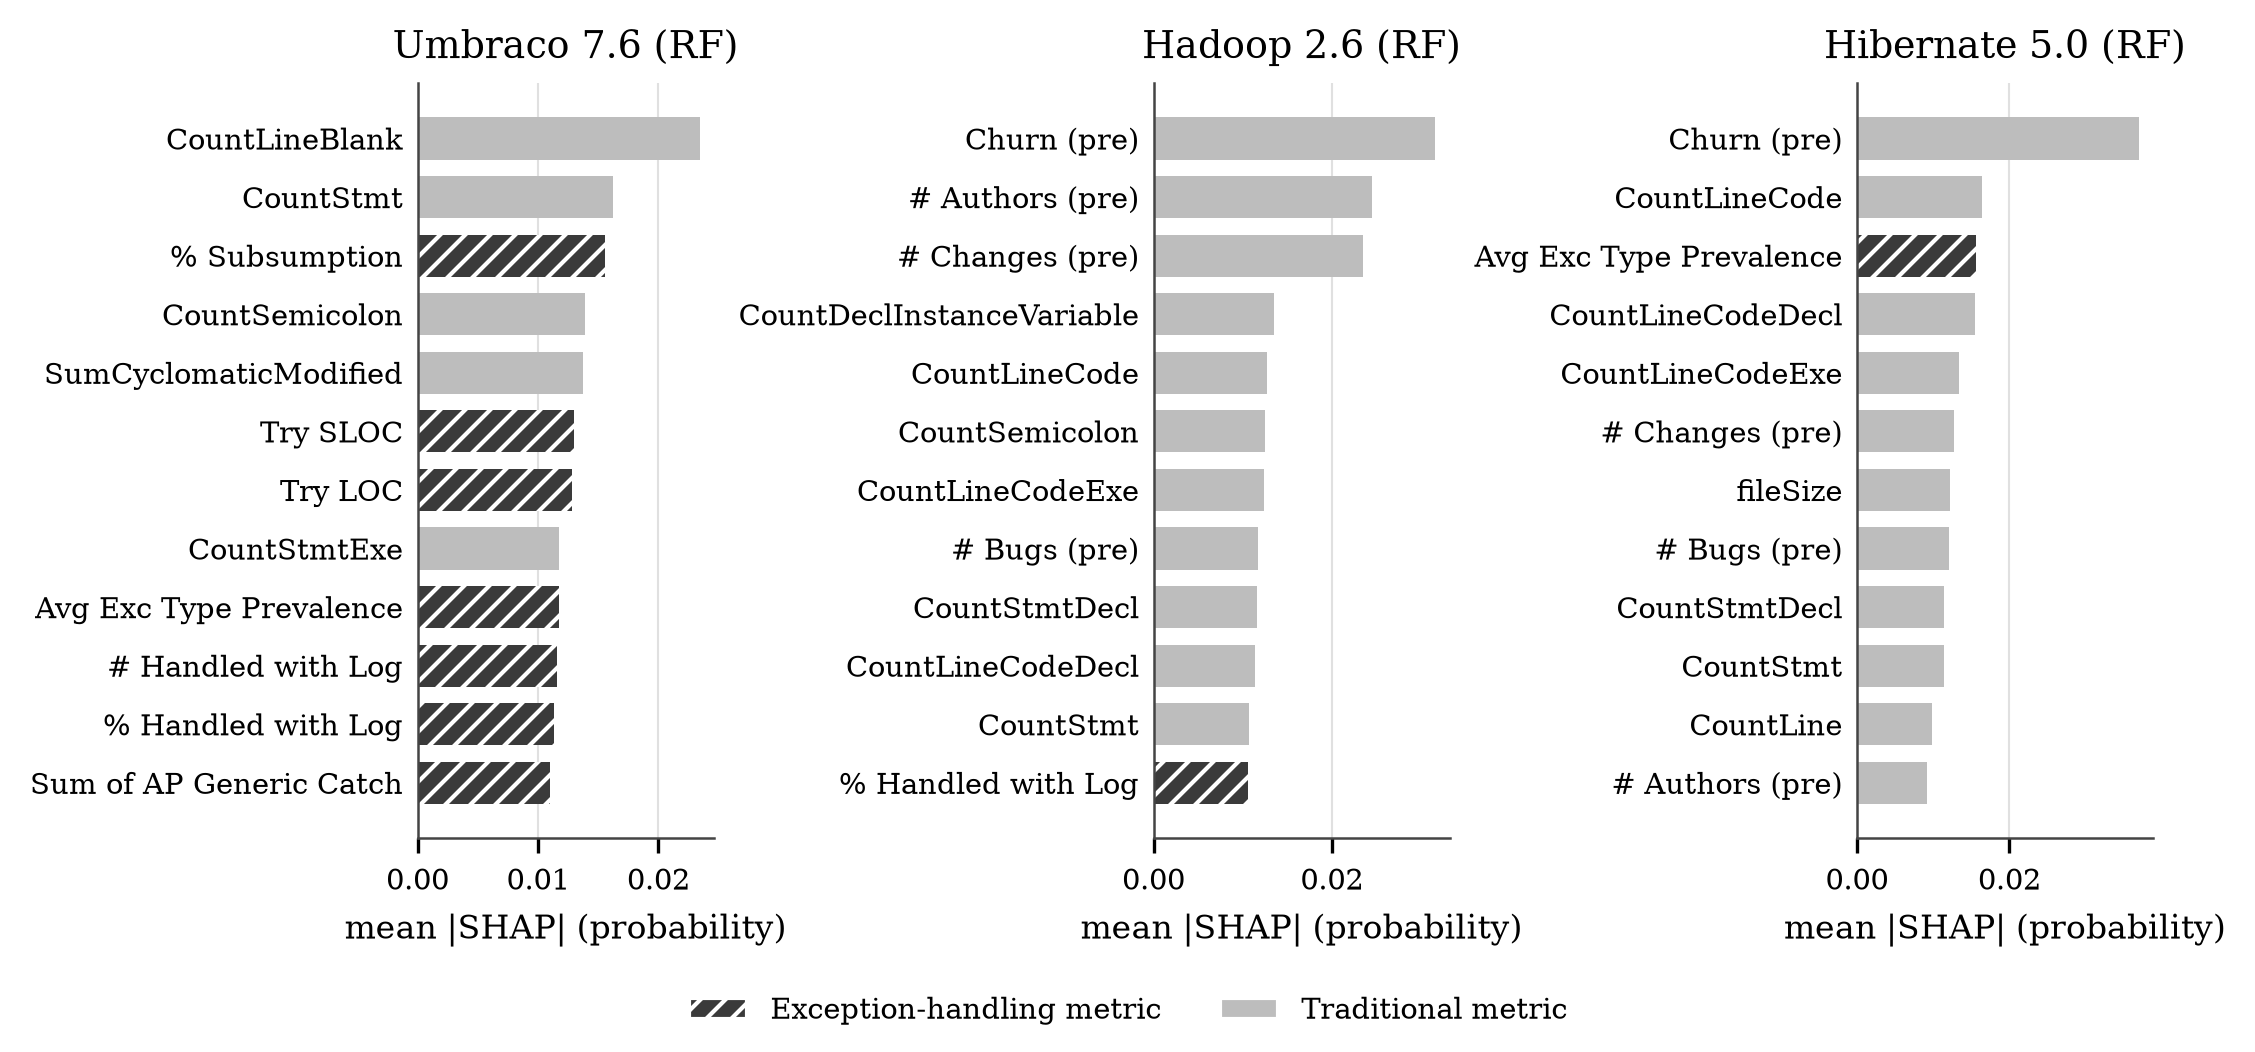

In [5]:
r = subprocess.run([sys.executable, 'src/explain/shap_analysis.py'], capture_output=True, text=True)
print(r.stdout[-4000:]); print(r.stderr[-2000:])
assert r.returncode == 0
display(Image('results/shap_bar_all.png'))

In [6]:
display(Markdown(Path('results/shap_alignment.md').read_text(encoding='utf-8')))

# RQ4: SHAP ranking of exception-handling features vs Phase 0 significant predictors

Generated by `python src/explain/shap_analysis.py`. SHAP on the best tree learner per project, refit on all files with >=1 catch block, TRAD+EH feature set.

## Umbraco 7.6

Top-10 EH features by mean |SHAP|:

| EH rank | Overall rank | Feature | Group | mean abs SHAP | Dir. | Phase 0 match (exact or proxy, abs rho > 0.7) |
|---:|---:|---|---|---:|:-:|---|
| 1 | 3 | X..Subsumption | try | 0.0155 | + | — |
| 2 | 6 | Try.SLOC | try | 0.0130 | + | — |
| 3 | 7 | Try.LOC | try | 0.0128 | + | — |
| 4 | 9 | Avg.Exc.Type.Prevalence | try | 0.0117 | + | — |
| 5 | 10 | X..Handled.with.Log | try | 0.0116 | + | — |
| 6 | 11 | X..Handled.with.Log.1 | try | 0.0113 | + | — |
| 7 | 12 | Sum.of.AP.Generic.Catch | catch | 0.0110 | + | Sum.of.AP.Generic.Catch (rho=1.00) |
| 8 | 18 | Avg..AP.Unhandled.exceptions | catch | 0.0089 | - | — |
| 9 | 21 | Avg..AP.Dummy.Handler | catch | 0.0084 | + | Avg..AP.Dummy.Handler (rho=1.00) |
| 10 | 22 | Sum.of.Num.Distinct.Methods | try | 0.0083 | + | — |

Phase 0 significant EH predictors (simplified BSFC/BSAP, bug-fixed run) and their SHAP rank: Avg..AP.Dummy.Handler (#21), Sum.of.AP.Generic.Catch (#12)

Top-10 EH SHAP features matching a Phase 0 significant EH predictor: **2/10**.

## Hadoop 2.6

Top-10 EH features by mean |SHAP|:

| EH rank | Overall rank | Feature | Group | mean abs SHAP | Dir. | Phase 0 match (exact or proxy, abs rho > 0.7) |
|---:|---:|---|---|---:|:-:|---|
| 1 | 12 | X..Handled.with.Log.1 | try | 0.0106 | + | X..Handled.with.Log.1 (rho=1.00) |
| 2 | 15 | X..Handled.with.Log | try | 0.0089 | + | X..Handled.with.Log.1 (rho=0.94) |
| 3 | 18 | Catch.LOC | catch | 0.0080 | + | Potentially.Recoverable (rho=0.86) |
| 4 | 19 | Avg.Catch.LOC | catch | 0.0077 | + | — |
| 5 | 25 | X..Specific | try | 0.0062 | + | X..Specific (rho=1.00) |
| 6 | 29 | Avg..AP.Overcatch | catch | 0.0058 | - | — |
| 7 | 33 | X..External.Doc | try | 0.0044 | - | — |
| 8 | 34 | Avg.Max.Depth | try | 0.0043 | - | — |
| 9 | 36 | X..Handled.with.Method.1 | try | 0.0042 | + | X..Handled.with.Method.1 (rho=1.00) |
| 10 | 37 | Sum.of.Num.Distinct.Methods | try | 0.0039 | + | Potentially.Recoverable (rho=0.73) |

Phase 0 significant EH predictors (simplified BSFC/BSAP, bug-fixed run) and their SHAP rank: AP.Log.and.Throw (#134), Avg..AP.Ignoring.Interrupted.Exception (#46), Potentially.Recoverable (#58), X..Handled.with.Log.1 (#12), X..Handled.with.Method.1 (#36), X..Propagated.1 (#57), X..Specific (#25), X..Try.in.Other (#140)

Top-10 EH SHAP features matching a Phase 0 significant EH predictor: **6/10**.

## Hibernate 5.0

Top-10 EH features by mean |SHAP|:

| EH rank | Overall rank | Feature | Group | mean abs SHAP | Dir. | Phase 0 match (exact or proxy, abs rho > 0.7) |
|---:|---:|---|---|---:|:-:|---|
| 1 | 3 | Avg.Exc.Type.Prevalence | try | 0.0157 | - | Avg.Exc.Type.Prevalence (rho=1.00) |
| 2 | 14 | X..Handled.with.Throw.Wrap | try | 0.0075 | - | X..Handled.with.Throw.Wrap (rho=1.00) |
| 3 | 19 | X..Propagated.1 | try | 0.0062 | + | — |
| 4 | 25 | Try.LOC | try | 0.0056 | + | — |
| 5 | 26 | Num.Distinct.Methods | try | 0.0054 | + | — |
| 6 | 29 | Avg...Invoked.Method | try | 0.0050 | + | Avg...Invoked.Method (rho=1.00) |
| 7 | 30 | Catch.SLOC | catch | 0.0049 | + | — |
| 8 | 32 | Sum.of.AP.Unhandled.exceptions | catch | 0.0045 | + | — |
| 9 | 34 | Sum.of.Num.Distinct.Methods | try | 0.0045 | + | — |
| 10 | 36 | Avg.Catch.LOC | catch | 0.0042 | + | — |

Phase 0 significant EH predictors (simplified BSFC/BSAP, bug-fixed run) and their SHAP rank: Avg...Invoked.Method (#29), Avg.Catch.SLOC (#38), Avg.Exc.Type.Prevalence (#3), Sum.of.AP.Dummy.Handler (#84), X..Handled.with.Throw.Wrap (#14)

Top-10 EH SHAP features matching a Phase 0 significant EH predictor: **3/10**.



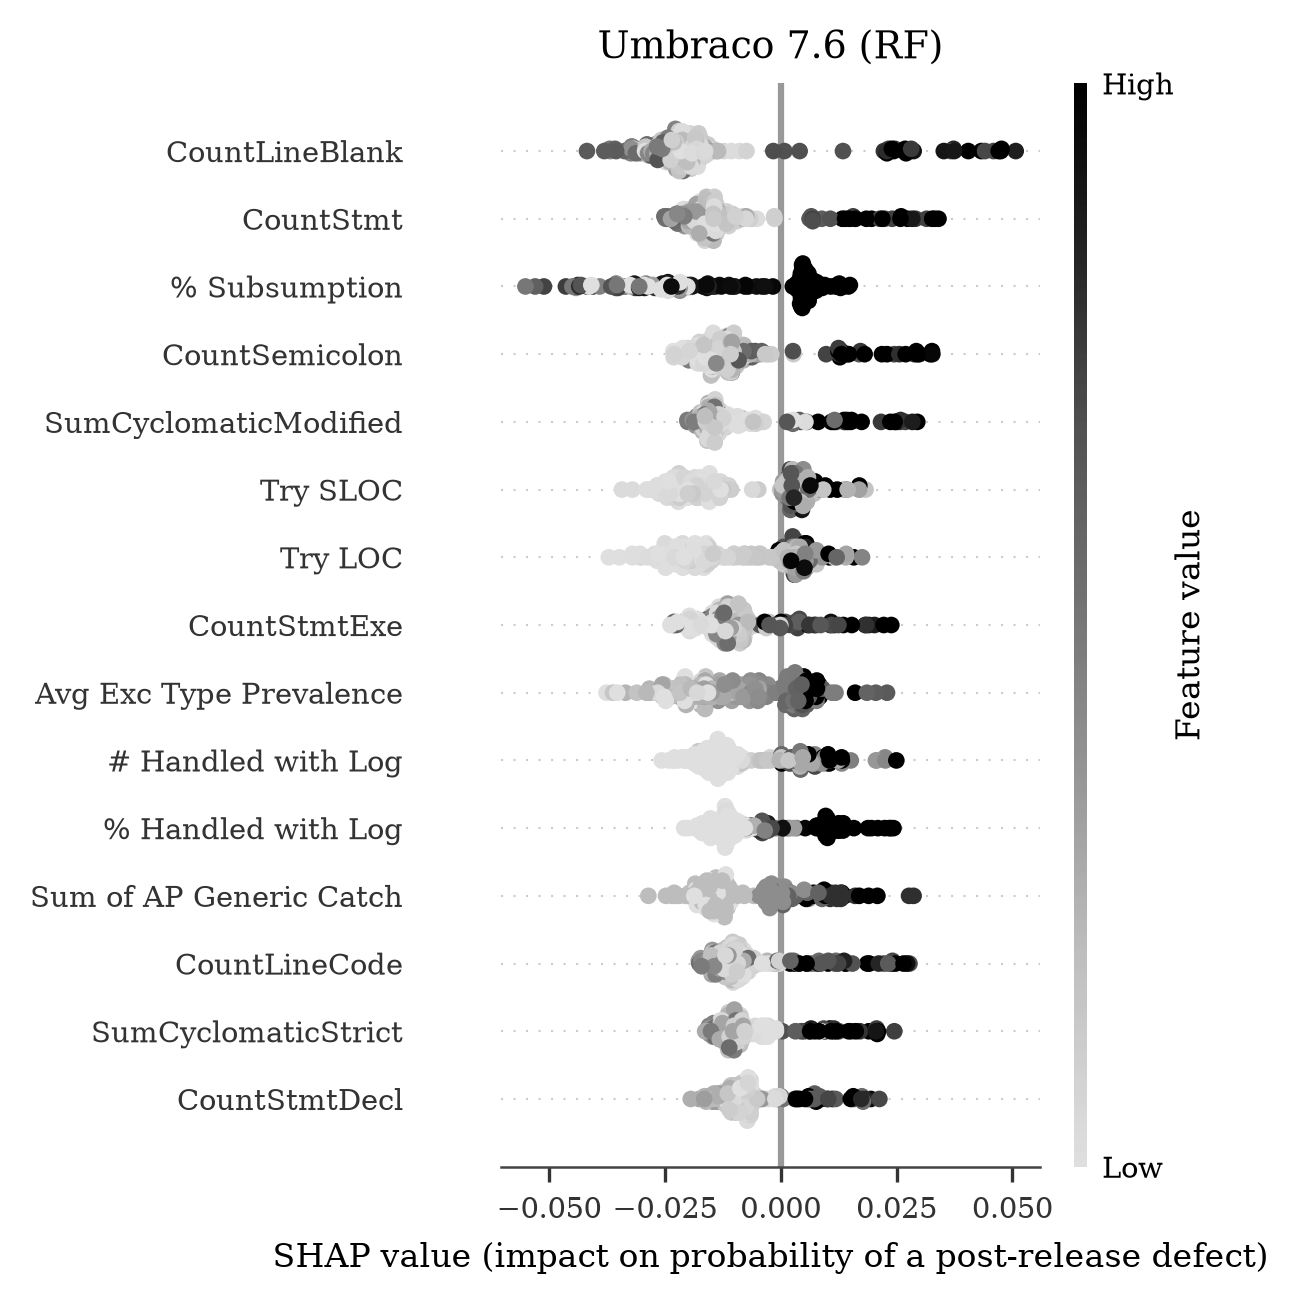

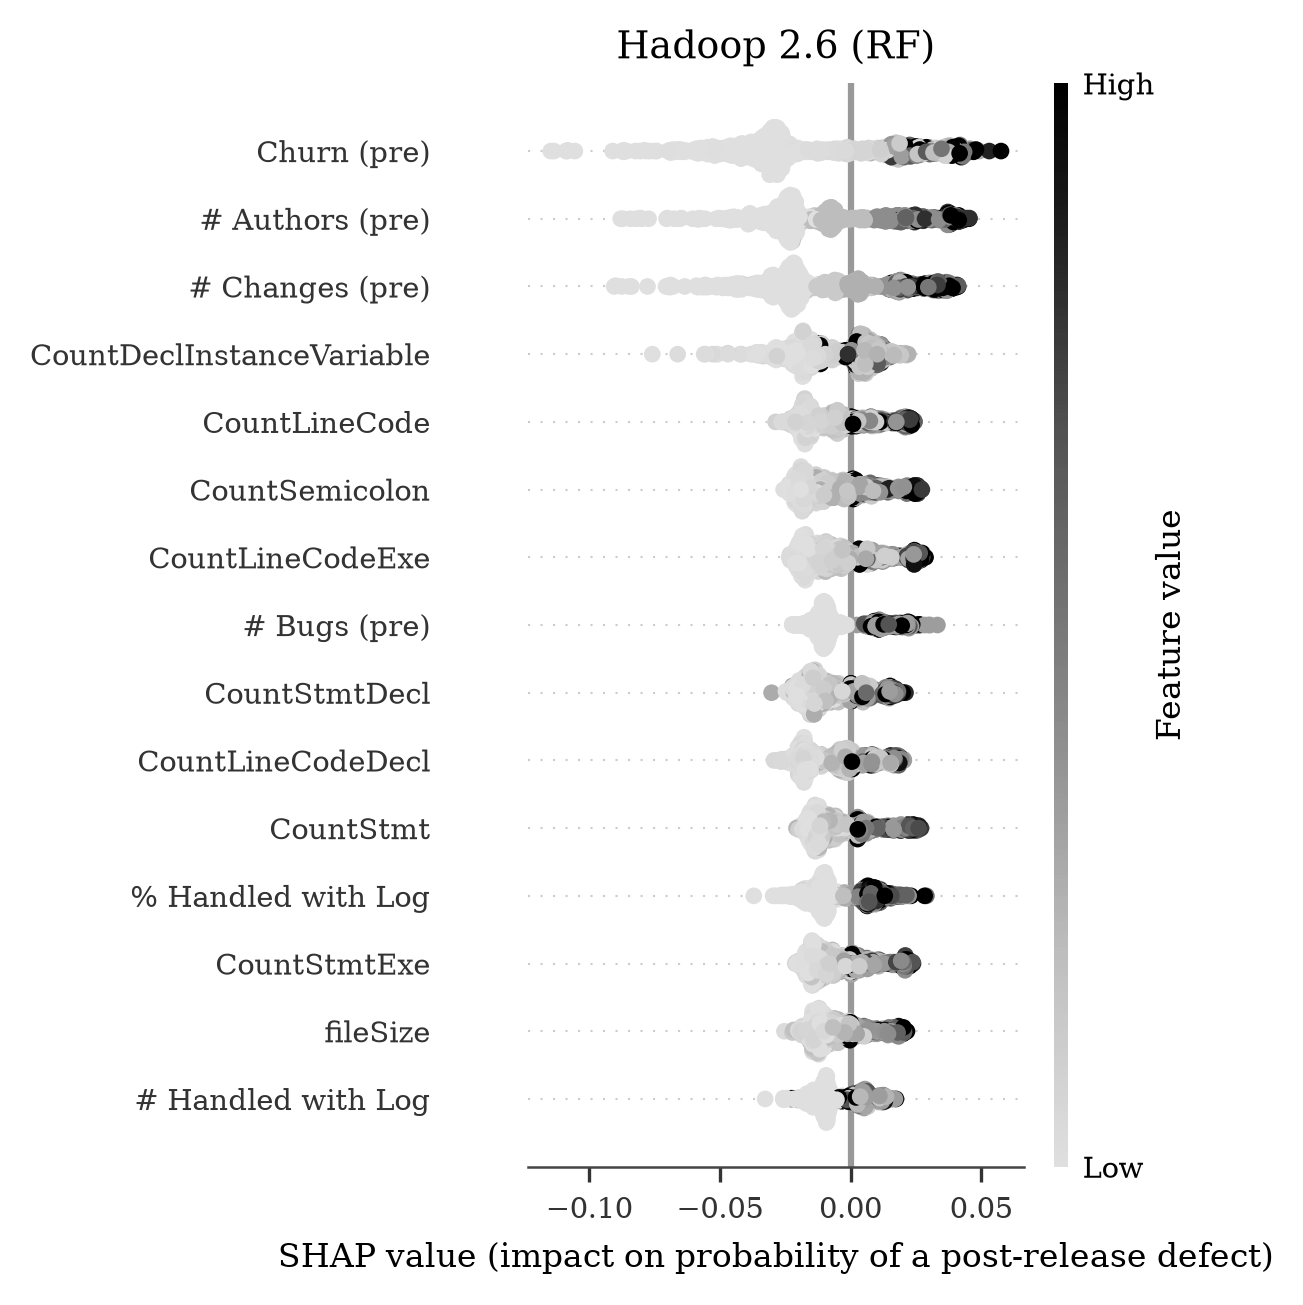

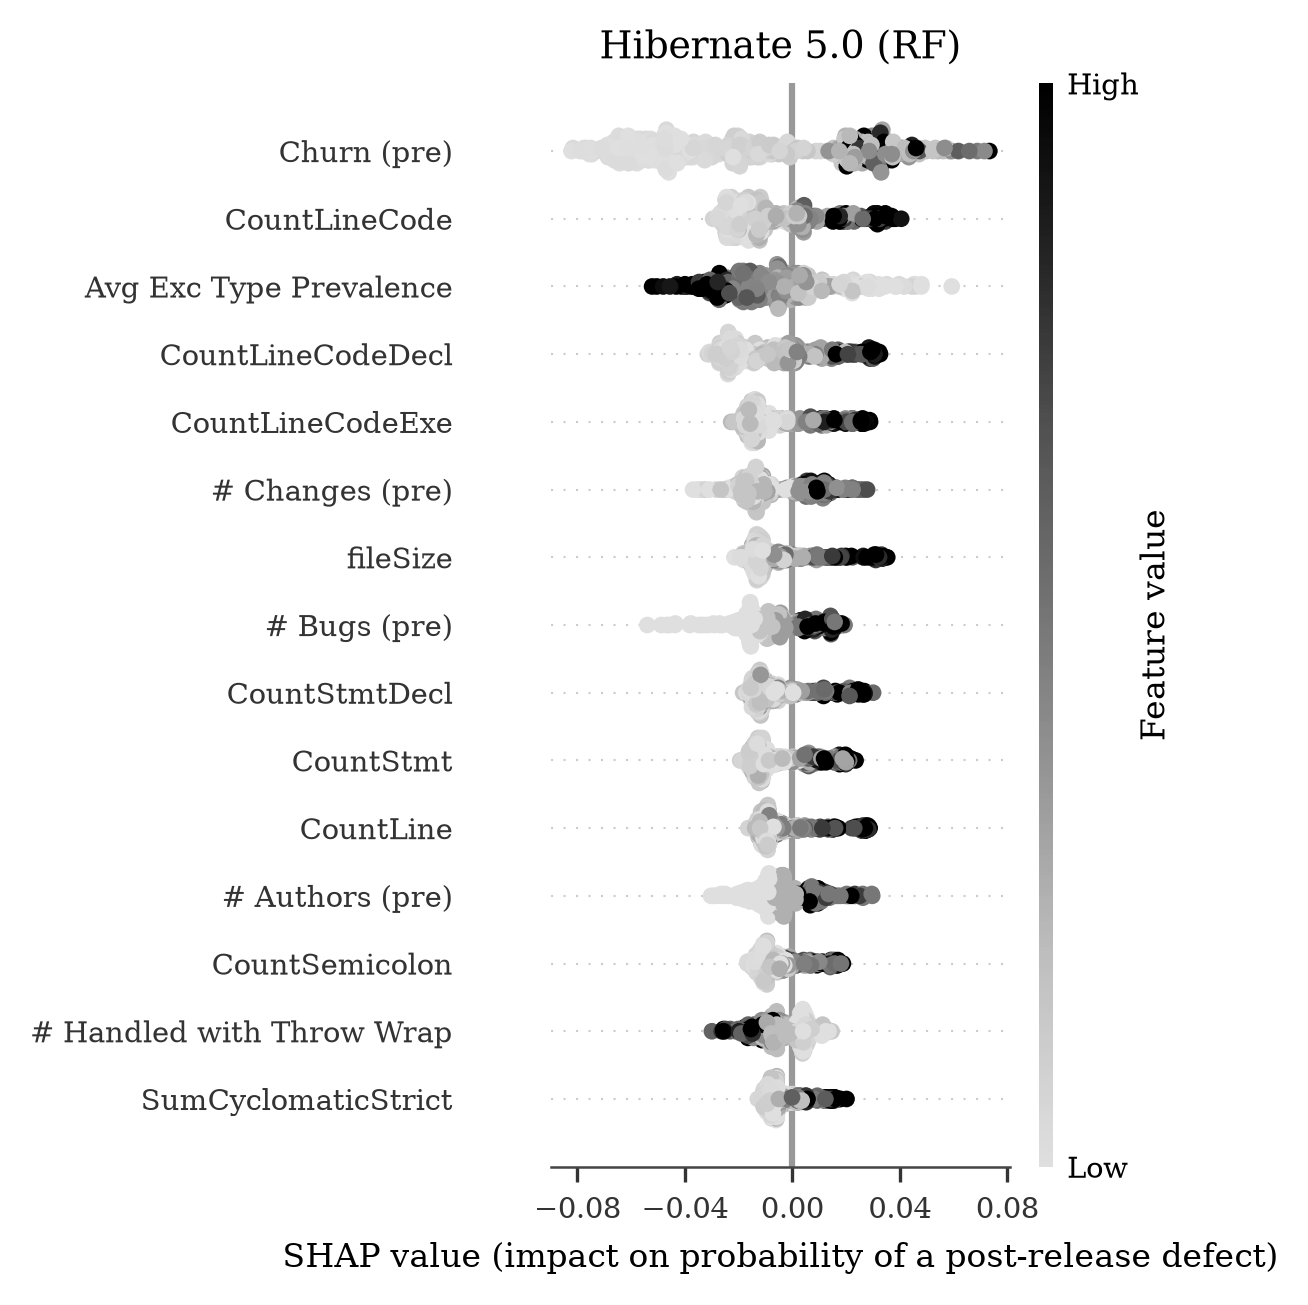

In [7]:
for p in PROJECTS:
    display(Image(f'results/shap_beeswarm_{p}.png', width=420))